# Tuần 6 — Thực hành: Cây quyết định, Random Forest và SVM

**Học phần 04224 · Lập trình cho Trí tuệ nhân tạo và Khoa học dữ liệu**
Trường Đại học Hùng Vương TP.HCM · Khoa Kỹ thuật Công nghệ

**CĐR:** CLO5.
**Thời lượng:** 3 tiết, khoảng **150 phút**. Dữ liệu mô phỏng dùng cho giảng dạy,
đọc từ `../lab_data/khachhang.csv`; không cần mạng sau khi cài thư viện.

**Kế hoạch:** 1. Cây & quá khớp (40′) · 2. Bốn mô hình (40′) · 3. SVM & thang đo (30′) · 4. Độ quan trọng & kết luận (40′).

**Nộp bài:** đổi tên thành `Tuan06_ThucHanh_<MSSV>.ipynb`.
Hoàn thành mọi `# TODO`, chạy **Restart & Run All**, giữ output và hình.
Nộp hình cây, đồ thị độ sâu, bảng bốn mô hình, thí nghiệm SVM, bảng độ quan trọng và các câu trả lời viết.

## Trước khi bắt đầu
Chạy Jupyter từ `lab_exercises/`. Dùng `random_state=42` và chạy các ô theo thứ tự.
Mỗi ô `# TODO` có chỉ dẫn trong phần văn bản ngay trước nó. `...` là chỗ cần điền.
Các kiểm tra về shape, xác suất và tính toàn vẹn dữ liệu phải chạy qua; điểm số mô hình
không phải mục tiêu để sửa đáp án cho khớp. Thứ hạng và thời gian có thể khác theo phiên bản/máy.

Dữ liệu khách hàng: `thang_gan_nhat` = số tháng kể từ đơn hàng gần nhất;
`tong_chi_tieu` = tổng chi tiêu (VND); `so_don` = số đơn;
`so_ticket_ho_tro` = số phiếu hỗ trợ. `roi_bo=1` là rời bỏ.
`ma_kh` là mã định danh; `kenh_ua_thich`, `tinh_tp` là phân loại và được để ngoài
phạm vi bài này. Không đưa nhãn hoặc mã định danh vào ma trận đặc trưng.

In [ ]:
import sys
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
FEATURES = ["thang_gan_nhat", "tong_chi_tieu", "so_don", "so_ticket_ho_tro"]
DATA_DIR = Path("../lab_data")
if not (DATA_DIR / "khachhang.csv").is_file():
    raise FileNotFoundError(f"Start Jupyter in lab_exercises/. Current folder: {Path.cwd()}")
customers = pd.read_csv(DATA_DIR / "khachhang.csv")
assert customers.shape == (1500, 8)
assert customers["ma_kh"].is_unique
assert not customers[FEATURES + ["roi_bo"]].isna().any().any()
X = customers[FEATURES].copy()
y = customers["roi_bo"].copy()
print("Python:", sys.version.split()[0], "| numpy:", np.__version__,
      "| pandas:", pd.__version__, "| sklearn:", sklearn.__version__)
print("Shape:", X.shape, "| churn fraction:", round(y.mean(), 4))
print(customers[FEATURES].describe().round(2).to_string())

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, RandomForestRegressor
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

C:\Users\PM401\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
C:\Users\PM401\AppData\Roaming\Python\Python313\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Python: 3.13.5 | numpy: 2.5.4 | pandas: 3.1.0 | sklearn: 1.9.1
Shape: (1500, 4) | churn fraction: 0.2087
       thang_gan_nhat  tong_chi_tieu   so_don  so_ticket_ho_tro
count         1500.00        1500.00  1500.00           1500.00
mean            14.20     7793408.00     5.98              1.48
std              6.84     4637241.09     2.45              1.13
min              0.00      222000.00     0.00              0.00
25%              9.40     4382250.00     4.00              0.00
50%             14.30     6947500.00     6.00              1.00
75%             18.90    10196500.00     8.00              2.00
max             39.20    34434000.00    19.00              3.00


## Task 1 — Cây nông và quá khớp (40 phút)
**1.1** Chia 60/20/20: lấy 20% test trước, rồi 25% của phần còn lại làm validation.
Fit bằng train; chọn mô hình bằng validation; chỉ dùng test ở Task 4.
**1.2** Fit cây `max_depth=3`, `min_samples_leaf=15`, seed 42. Vẽ toàn bộ cây
với tên đặc trưng và hai lớp. Chọn **ba đường đi từ gốc tới lá**, viết mỗi luật thành
“nếu … thì …”; nêu cả số mẫu và tỷ lệ lớp tại lá. Gini đo độ lẫn lớp, không phải độ chính xác.
**1.3** Quét độ sâu `[1,2,3,4,6,10,None]`, cùng `min_samples_leaf=1` để thấy tác động
của độ sâu. Vẽ ROC AUC train/validation; chọn độ sâu bằng validation AUC.

**Kiểm tra:** shape phải là `(900,4)/(300,4)/(300,4)`. Không kỳ vọng cây sâu nhất tốt nhất.

In [2]:
# TODO 1.1 — 60% train / 20% validation / 20% test; stratify BOTH splits.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=RANDOM_STATE, stratify=y_dev)
assert (len(X_train), len(X_val), len(X_test)) == (900, 300, 300)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_dev.index).isdisjoint(X_test.index)
print(pd.DataFrame({"rows": [len(y_train), len(y_val), len(y_test)],
                    "churn_fraction": [y_train.mean(), y_val.mean(), y_test.mean()]},
                   index=["train", "validation", "test"]))

            rows  churn_fraction
train        900        0.208889
validation   300        0.206667
test         300        0.210000


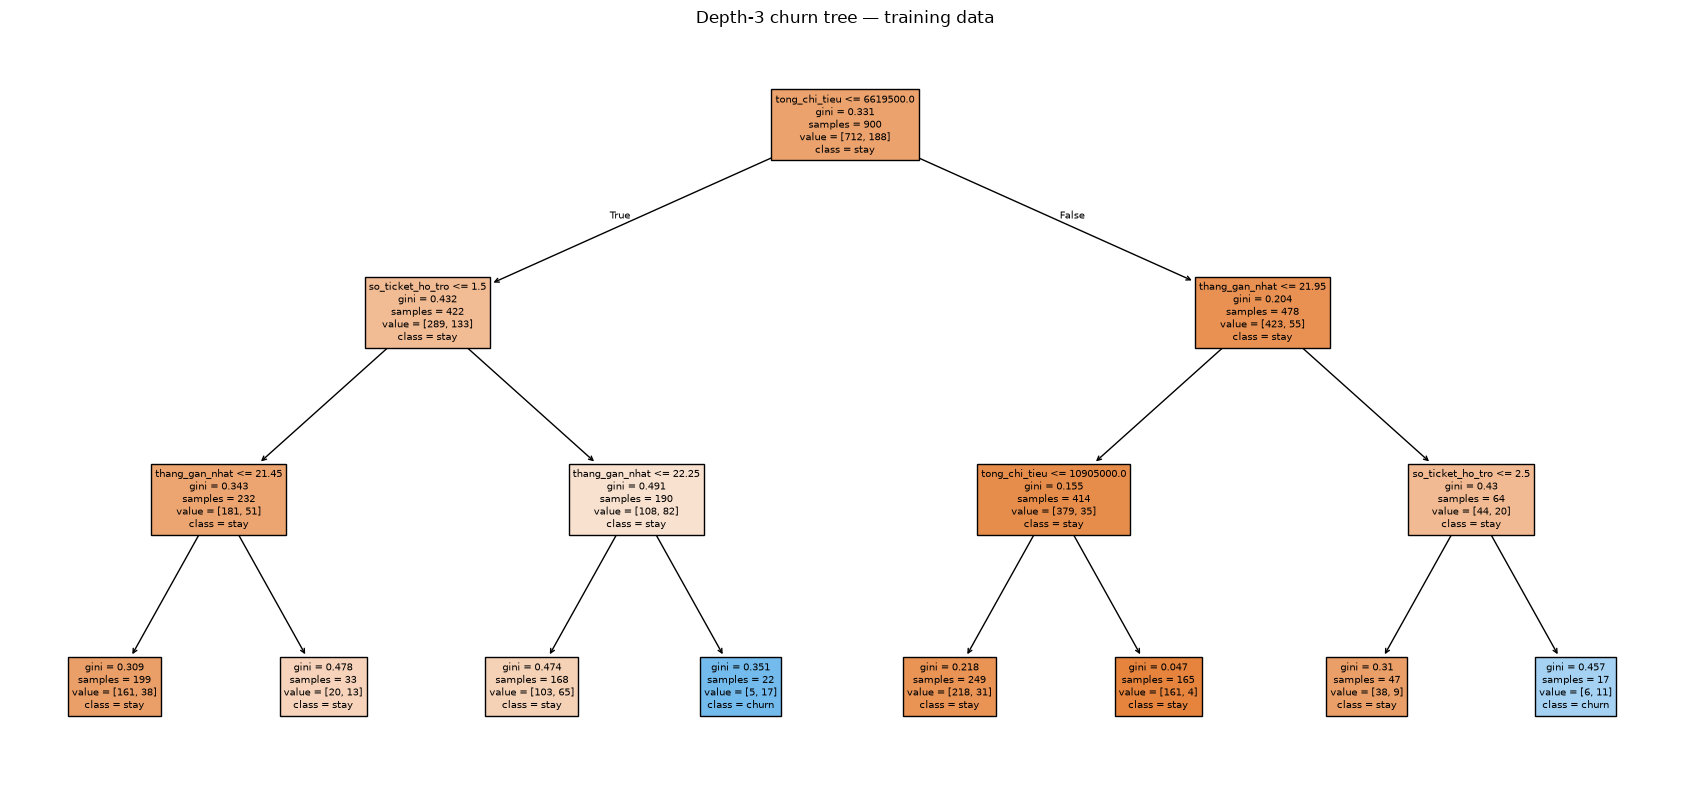

In [3]:
# TODO 1.2 — Fit and plot the shallow tree.
shallow = DecisionTreeClassifier(max_depth=3, min_samples_leaf=15, random_state=RANDOM_STATE).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(17, 8))
plot_tree(shallow, feature_names=FEATURES, class_names=["stay", "churn"], filled=True, ax=ax)
ax.set_title("Depth-3 churn tree — training data")
plt.tight_layout()
plt.show()
assert shallow.get_depth() <= 3

depth  train_auc  val_auc
    1     0.6508   0.6791
    2     0.7185   0.6936
    3     0.7498   0.7058
    4     0.7841   0.7010
    6     0.8541   0.7261
   10     0.9755   0.6540
 None     1.0000   0.5745


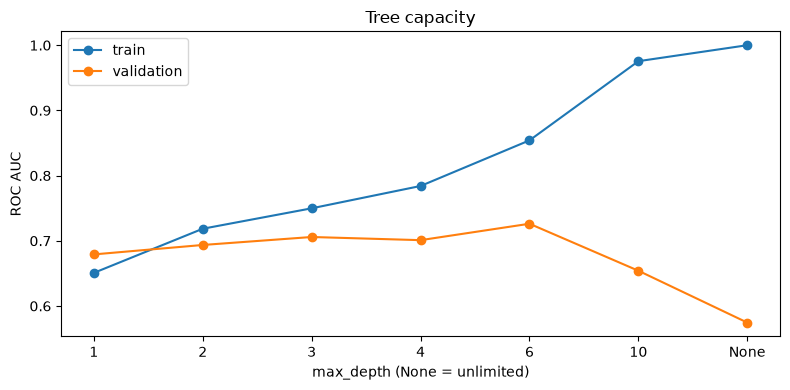

Selected depth: 6


In [4]:
# TODO 1.3 — Fit each depth and record probability-based AUC on train and validation.
depths = [1, 2, 3, 4, 6, 10, None]
depth_rows = []
for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=1, random_state=RANDOM_STATE).fit(X_train, y_train)
    depth_rows.append({"depth": str(depth),
                       "train_auc": roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1]), "val_auc": roc_auc_score(y_val, tree.predict_proba(X_val)[:, 1])})
depth_table = pd.DataFrame(depth_rows)
print(depth_table.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depth_table["depth"], depth_table["train_auc"], "o-", label="train")
ax.plot(depth_table["depth"], depth_table["val_auc"], "o-", label="validation")
ax.set(xlabel="max_depth (None = unlimited)", ylabel="ROC AUC", title="Tree capacity")
ax.legend()
plt.tight_layout()
plt.show()
best_depth = depths[int(depth_table["val_auc"].to_numpy().argmax())]
print("Selected depth:", best_depth)

**Viết 1:** ba luật của cây; độ sâu được chọn; chênh lệch train/validation có gợi ý quá khớp không? Dẫn số liệu.

## Task 2 — So sánh bốn mô hình (40 phút)
**2.1** Hoàn thành bốn estimator: cây với `best_depth`; Random Forest 150 cây,
`min_samples_leaf=5`, `n_jobs=1`; HistGradientBoosting với `max_leaf_nodes=7`,
`learning_rate=0.05`, `max_iter=100`; và pipeline `StandardScaler → SVC(C=1, kernel='rbf')`.
Mọi mô hình ngẫu nhiên dùng seed 42. Thêm `DummyClassifier(strategy='most_frequent')` làm baseline.
**2.2** Hàm `compare` fit trên train, đo **thời gian fit**, accuracy, recall lớp 1,
F1 và ROC AUC trên validation. SVC dùng `decision_function`, các mô hình khác dùng xác suất.
Không cần `probability=True`: ROC AUC chấp nhận decision score.
**2.3** Chọn một trong bốn mô hình bằng validation AUC, giữ nguyên cấu hình tới Task 4.

In [5]:
# TODO 2.1
models = {
    "Tree": DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=150, min_samples_leaf=5, n_jobs=1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(max_leaf_nodes=7, learning_rate=0.05, max_iter=100, random_state=RANDOM_STATE),
    "Scaled SVM": make_pipeline(StandardScaler(), SVC(C=1, kernel='rbf', random_state=RANDOM_STATE)),
    "Majority": DummyClassifier(strategy="most_frequent"),
}

def decision_scores(model, data):
    if hasattr(model, "decision_function"):
        return model.decision_function(data)
    return model.predict_proba(data)[:, 1]

def compare(name, model):
    started = perf_counter()
    # TODO 2.2 — fit on TRAIN, then predict on VALIDATION.
    model.fit(X_train, y_train)
    fit_seconds = perf_counter() - started
    pred = model.predict(X_val)
    score = decision_scores(model, X_val)
    return {"model": name, "accuracy": accuracy_score(y_val, pred),
            "recall": recall_score(y_val, pred, zero_division=0),
            "f1": f1_score(y_val, pred, zero_division=0),
            "auc": roc_auc_score(y_val, score), "fit_s": fit_seconds}

comparison = pd.DataFrame([compare(name, model) for name, model in models.items()])
print(comparison.round(4).to_string(index=False))
winner_name = comparison[comparison["model"] != "Majority"].sort_values(
    "auc", ascending=False, kind="stable").iloc[0]["model"]
print("Validation-selected winner:", winner_name)
assert comparison["auc"].between(0, 1).all()

            model  accuracy  recall     f1    auc  fit_s
             Tree    0.7867  0.2903 0.3600 0.7261 0.0049
    Random Forest    0.7833  0.2097 0.2857 0.7382 0.2569
Gradient Boosting    0.7933  0.2581 0.3404 0.7431 0.0812
       Scaled SVM    0.7833  0.0161 0.0299 0.6875 0.0254
         Majority    0.7933  0.0000 0.0000 0.5000 0.0006
Validation-selected winner: Gradient Boosting


**Viết 2:** mô hình nào tốt nhất theo AUC? Có mô hình accuracy cao nhưng recall thấp không? Vì sao thời gian một lần chạy chưa đủ để kết luận trên mọi máy?

## Task 3 — SVM và thang đo (30 phút)
**3.1** Fit SVC thô với cùng `C=1, kernel='rbf'`, so với SVM đã chuẩn hóa ở Task 2.
In accuracy, recall, AUC và `_gamma` (chỉ dùng thuộc tính nội bộ này để chẩn đoán).
**3.2** Đổi **đơn vị** `tong_chi_tieu` từ VND sang triệu VND trên cả train và validation,
giữ các cột khác. Fit lại SVM thô và SVM có scaler, so độ chênh decision score.
Không giả định SVM thô chắc chắn giảm AUC; đo kết quả thật.

In [6]:
# TODO 3.1–3.2
raw_svm = SVC(C=1, kernel="rbf", random_state=RANDOM_STATE).fit(X_train, y_train)
unit_train, unit_val = X_train.copy(), X_val.copy()
unit_train["tong_chi_tieu"] /= 1_000_000
unit_val["tong_chi_tieu"] /= 1_000_000
raw_million = SVC(C=1, kernel="rbf").fit(unit_train, y_train)
scaled_million = make_pipeline(StandardScaler(), SVC(C=1, kernel="rbf", random_state=RANDOM_STATE)).fit(unit_train, y_train)
svm_rows = []
for name, model, data in [("raw VND", raw_svm, X_val),
                           ("scaled VND", models["Scaled SVM"], X_val),
                           ("raw million VND", raw_million, unit_val),
                           ("scaled million VND", scaled_million, unit_val)]:
    pred = model.predict(data)
    svc = model.named_steps["svc"] if hasattr(model, "named_steps") else model
    svm_rows.append({"model": name, "accuracy": accuracy_score(y_val, pred),
                     "recall": recall_score(y_val, pred, zero_division=0),
                     "auc": roc_auc_score(y_val, model.decision_function(data)), "gamma": svc._gamma})
print(pd.DataFrame(svm_rows).to_string(index=False))
unit_difference = np.max(np.abs(models["Scaled SVM"].decision_function(X_val)
                                - scaled_million.decision_function(unit_val)))
print("Scaled SVM max score difference after changing units:", unit_difference)
assert unit_difference < 1e-5

             model  accuracy   recall      auc        gamma
           raw VND  0.793333 0.000000 0.433993 1.493701e-14
        scaled VND  0.783333 0.016129 0.687517 2.500000e-01
   raw million VND  0.786667 0.016129 0.679927 6.401734e-03
scaled million VND  0.783333 0.016129 0.687517 2.500000e-01
Scaled SVM max score difference after changing units: 4.2299497238218464e-14


**Viết 3:** giải thích vì sao khoảng cách Euclid và `gamma='scale'` phụ thuộc đơn vị. StandardScaler khắc phục điều gì? Vì sao không fit scaler lên validation/test?

## Task 4 — Độ quan trọng và đánh giá cuối (40 phút)
**4.1** Trên rừng đã fit ở Task 2, tính permutation importance **trên validation**,
`scoring='roc_auc'`, `n_repeats=10`, seed 42. Ghép mean, std với `feature_importances_`
và vẽ biểu đồ ngang có error bar. Hai loại độ quan trọng có cùng đơn vị không?
**4.2** Đánh giá winner đã chọn đúng một lần trên test: accuracy, recall, F1, AUC,
ma trận nhầm lẫn. Không đổi winner sau khi xem test.
**4.3** Viết 5–7 câu khuyến nghị: chỉ số ưu tiên, baseline, thời gian, khả năng giải thích,
và một giới hạn của kết quả trên dữ liệu mô phỏng. Độ quan trọng không chứng minh nhân quả.

         feature  impurity  auc_drop    std
          so_don    0.1014   -0.0101 0.0061
so_ticket_ho_tro    0.1443    0.0439 0.0255
  thang_gan_nhat    0.3364    0.0581 0.0231
   tong_chi_tieu    0.4179    0.1228 0.0287


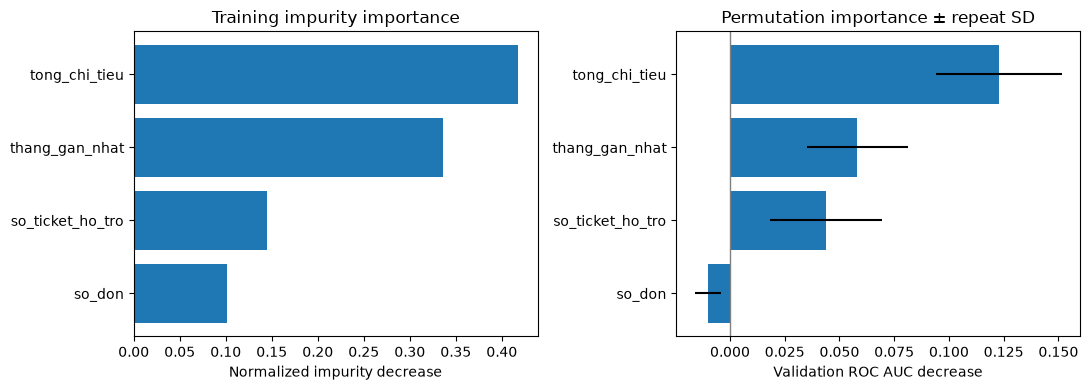

In [7]:
# TODO 4.1
forest = models["Random Forest"]
perm = permutation_importance(forest, X_val, y_val, scoring='roc_auc', n_repeats=10, random_state=RANDOM_STATE)
importance = pd.DataFrame({"feature": FEATURES, "impurity": forest.feature_importances_,
                           "auc_drop": perm.importances_mean, "std": perm.importances_std})
importance = importance.sort_values("auc_drop")
print(importance.round(4).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].barh(importance["feature"], importance["impurity"])
axes[0].set(xlabel="Normalized impurity decrease", title="Training impurity importance")
axes[1].barh(importance["feature"], importance["auc_drop"], xerr=importance["std"])
axes[1].axvline(0, color="grey", lw=1)
axes[1].set(xlabel="Validation ROC AUC decrease", title="Permutation importance ± repeat SD")
plt.tight_layout()
plt.show()

Frozen winner: Gradient Boosting
{'accuracy': 0.7866666666666666, 'recall': 0.15873015873015872, 'f1': 0.23809523809523808, 'auc': 0.7377268769673833}


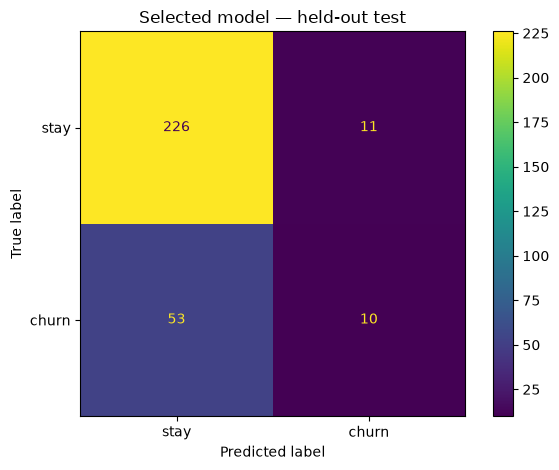

In [8]:
# TODO 4.2 — winner is already fitted on training rows only.
winner = models[winner_name]
test_pred = winner.predict(X_test)
test_score = decision_scores(winner, X_test)
print("Frozen winner:", winner_name)
print({"accuracy": accuracy_score(y_test, test_pred),
       "recall": recall_score(y_test, test_pred, zero_division=0),
       "f1": f1_score(y_test, test_pred, zero_division=0),
       "auc": roc_auc_score(y_test, test_score)})
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["stay", "churn"])
plt.title("Selected model — held-out test")
plt.tight_layout()
plt.show()

## Mở rộng — Trở lại bẫy đa cộng tuyến của Tuần 5 (không bắt buộc)
Nạp `nha_dat.csv`; dùng 11 cột số gồm cặp diện tích và bốn cột nhiễu, bỏ ID/`quan`/target.
So Ridge chuẩn hóa với rừng hồi quy trên split 80/20 seed 42. In R², và độ quan trọng của
hai cột diện tích. Vì sao rừng không có hệ số ±432? Vì sao hai cột thay thế nhau làm mỗi
cột có permutation importance thấp? **Cộng** hai importance riêng có bằng hoán vị đồng thời không?

In [9]:
# TODO — optional stretch
houses = pd.read_csv(DATA_DIR / "nha_dat.csv")
housing_X = houses.drop(columns=["ma_nha", "quan", "gia_ty_vnd"])
ha, hb, ya, yb = train_test_split(housing_X, houses["gia_ty_vnd"], test_size=0.2, random_state=RANDOM_STATE)
regressors = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0, random_state=RANDOM_STATE)),
    "Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE)
}
for name, model in regressors.items():
    model.fit(ha, ya)
    print(name, "R2:", round(r2_score(yb, model.predict(hb)), 4))
rf_reg = regressors["Forest"]
hp = permutation_importance(rf_reg, hb, yb, scoring="r2", n_repeats=5, random_state=RANDOM_STATE)
print(pd.DataFrame({"feature": housing_X.columns, "impurity": rf_reg.feature_importances_,
                    "R2_drop": hp.importances_mean}).head(2).to_string(index=False))

Ridge R2: 0.6549
Forest R2: 0.6073
       feature  impurity  R2_drop
  dien_tich_m2  0.270804 0.179116
dien_tich_sqft  0.426742 0.430590


## Kiểm tra trước khi nộp
- [ ] Hoàn thành bốn task chính, không còn `...` hoặc `TODO` trong phần mã bắt buộc.
- [ ] Trả lời cả bốn phần viết bằng số liệu của chính lần chạy này.
- [ ] Mọi hình có tên, nhãn trục và chú giải khi cần; giữ bảng và output.
- [ ] **Restart & Run All** chạy qua; dùng seed 42 trừ thí nghiệm đổi seed được chỉ định.
- [ ] Nếu bỏ phần mở rộng, xóa ô mã mở rộng chưa điền trước khi Run All và ghi “không thực hiện”.
- [ ] Đổi tên tệp có MSSV và nộp trước khi rời phòng máy.